In [29]:
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.arima_process import ArmaProcess
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.tsa.stattools import adfuller
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [4]:
np.random.seed(42)
ma2 = np.array([1, 0.9, 0.3])
ar2 = np.array([1, 0, 0])

MA2_process = ArmaProcess(ar2,ma2).generate_sample(nsample=1000)

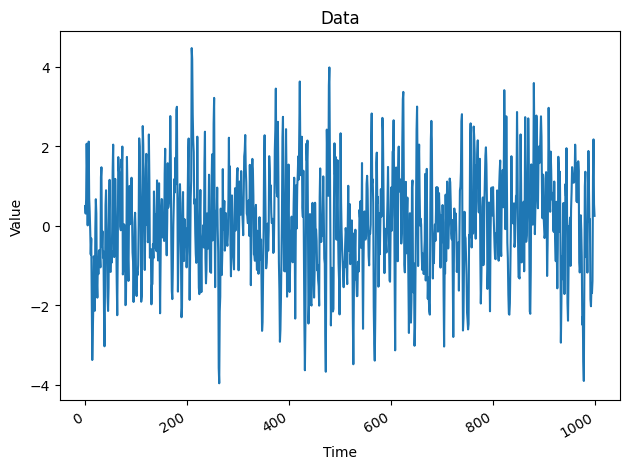

In [39]:
fig, ax = plt.subplots()
ax.plot(MA2_process)
ax.set_xlabel("Time")
ax.set_ylabel("Value")
ax.set_title("Data")

fig.autofmt_xdate()
plt.tight_layout()

In [7]:
#ADFuller test
from statsmodels.tsa.stattools import adfuller

ADF_result = adfuller(MA2_process)
print(f"ADF statisitc:, {ADF_result[0]}")
print(f"p-value:, {ADF_result[1]}")

ADF statisitc:, -14.00544430919449
p-value:, 3.795601616713556e-26


The ADF is a large negative number and the p-value is greater than 0.05 and so the data is stationary and so no need to difference.

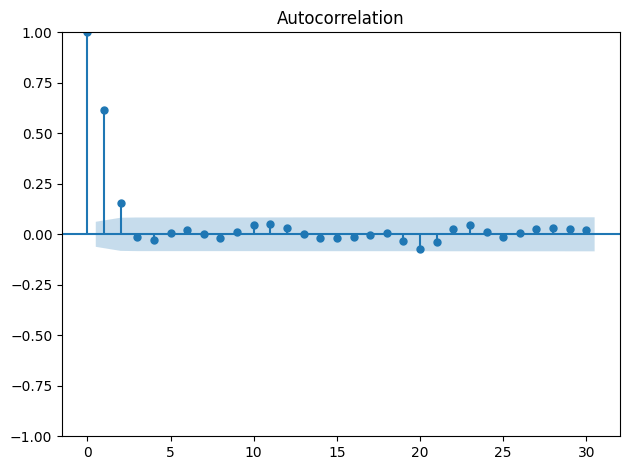

In [8]:
#ACF
from statsmodels.graphics.tsaplots import plot_acf
plot_acf(MA2_process, lags=30)
plt.tight_layout()

Coefficients are significant until lag 2 and so has order 2.

In [21]:
df = pd.DataFrame({"value": MA2_process})

train = df[:800]
test = df[800:]

In [ ]:
#function for rolling forecasts on a horizon

def rolling_forecast(df: pd.DataFrame, train_len: int, horizon: int, window: int, method: str):  #horizon how far you want to look into future
    
    total_len = train_len + horizon
    
    if method == 'mean':
        pred_mean = []
        
        for i in range(train_len, total_len, window):
            mean = np.mean(df[:i].values)
            pred_mean.extend(mean for _ in range(window))

        return pred_mean

    elif method == 'last':
        pred_last_value = []
        
        for i in range(train_len, total_len, window):
            last_value = df[:i].iloc[-1].values[0]
            pred_last_value.extend(last_value for _ in range(window))
            
        return pred_last_value
    
    elif method == 'MA':
        pred_MA = []
        
        for i in range(train_len, total_len, window):
            model = SARIMAX(df[:i], order=(0,0,2))
            res = model.fit(disp=False)
            predictions = res.get_prediction(0, i + window - 1)
            oos_pred = predictions.predicted_mean.iloc[-window:]
            pred_MA.extend(oos_pred)
            
        return pred_MA

In [ ]:
#Generating a list of predictions
pred_df = test.copy()

TRAIN_LEN = len(train)
HORIZON = len(test)
WINDOW = 2  #move forward 2 observations at a time

pred_mean = rolling_forecast(df, TRAIN_LEN, HORIZON, WINDOW, 'mean')  #using rolling forecast def from previous
pred_last_value = rolling_forecast(df, TRAIN_LEN, HORIZON, WINDOW, 'last')
pred_MA2 = rolling_forecast(df, TRAIN_LEN, HORIZON, WINDOW, 'MA')

test.loc[:, 'pred_mean'] = pred_mean
test.loc[:, 'pred_last_value'] = pred_last_value
test.loc[:, 'pred_MA2'] = pred_MA2

test.head()

C:\Users\Invate\AppData\Local\Temp\ipykernel_23232\346154491.py:12: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  test.loc[:, 'pred_mean'] = pred_mean
C:\Users\Invate\AppData\Local\Temp\ipykernel_23232\346154491.py:13: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  test.loc[:, 'pred_last_value'] = pred_last_value
C:\Users\Invate\AppData\Local\Temp\ipykernel_23232\346154491.py:14: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer

,value,pred_mean,pred_last_value,pred_MA2
800,0.973560,-0.017430,0.259693,0.065366
801,0.337338,-0.017430,0.259693,0.017984
802,-0.086834,-0.015752,0.337338,-0.180397
803,-0.530580,-0.015752,0.337338,-0.116820
804,-0.821708,-0.016481,-0.530580,-0.405768


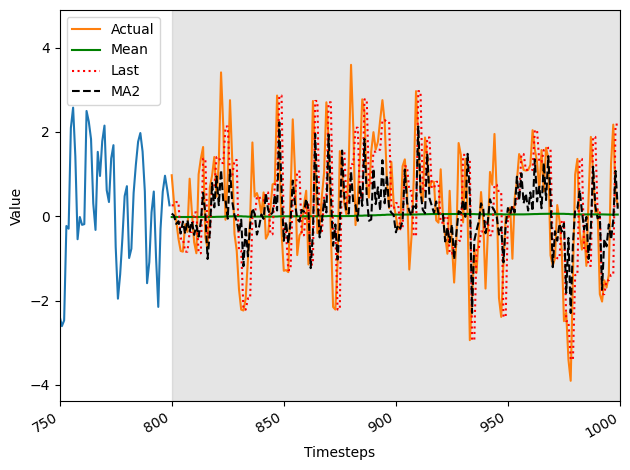

In [ ]:
fig, ax = plt.subplots()

ax.plot(train)
ax.plot(test['value'], label='Actual')
ax.plot(test['pred_mean'], 'g-', label='Mean')
ax.plot(test['pred_last_value'], 'r:', label='Last')
ax.plot(test['pred_MA2'], 'k--', label='MA2')

ax.set_xlabel('Timesteps')
ax.set_ylabel('Value')
ax.set_title("Forecasts")

ax.legend(loc='best')

ax.axvspan(800, 1000, color='#808080', alpha=0.2)

plt.xlim(750, 1000)
fig.autofmt_xdate()
plt.tight_layout()

In [35]:
from sklearn.metrics import mean_squared_error

mse_mean = mean_squared_error(test['value'], test['pred_mean'])
mse_last = mean_squared_error(test['value'], test['pred_last_value'])
mse_MA = mean_squared_error(test['value'], test['pred_MA2'])

print(mse_mean, mse_last, mse_MA)

1.8635013982365882 1.988201688527919 1.2323542190669703


From the MSE the best model is the MA(2) since its the lowest of the three values.

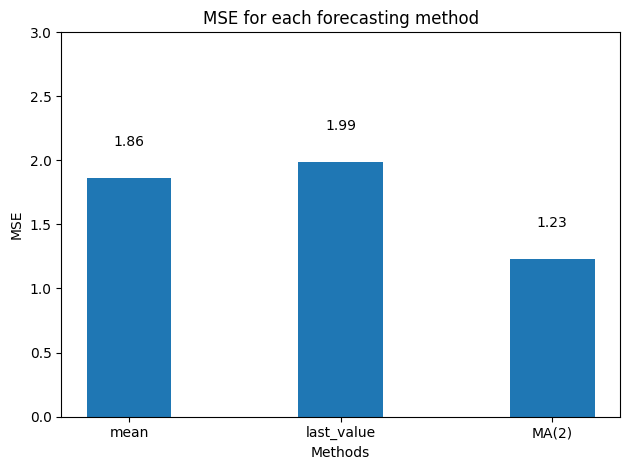

In [38]:
fig, ax = plt.subplots()

x = ['mean', 'last_value', 'MA(2)']
y = [mse_mean, mse_last, mse_MA]

ax.bar(x, y, width=0.4)
ax.set_xlabel('Methods')
ax.set_ylabel('MSE')
ax.set_ylim(0, 3)
ax.set_title("MSE for each forecasting method")

for index, value in enumerate(y):
    plt.text(x=index, y=value+0.25, s=str(round(value, 2)), ha='center')

plt.tight_layout()